# Performing Experiment with QFT 
1. Phase to amplitude readout (inverse qft)
2. Period finding (qft)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

In [2]:
# Use QFTGate with fallback to QFT
try:
    from qiskit.circuit.library import QFTGate
    def make_qft(n: int, inverse: bool = False):
        gate = QFTGate(num_qubits=n)
        return gate.inverse() if inverse else gate
except ImportError:
    from qiskit.circuit.library import QFT
    def make_qft(n: int, inverse: bool = False):
        return QFT(num_qubits=n, inverse=inverse, do_swaps=True)

sampler = StatevectorSampler()

## Converting Hidden Phase into Amplitude (Exact vs. Inexact)

Suppose a 3-qubit state ($N = 8$) encodes a frequency/phase $\omega$ purely in relative phases:

$$\ket{\psi_\omega} = \frac{1}{\sqrt{8}} \sum_{j=0}^{7} e^{2\pi i \omega j / 8} \ket{j}$$

Direct measurement gives a flat distribution across all 8 states, whereas applying $\text{QFT}^\dagger$ concentrates amplitude onto $\ket{\omega}$:

In [3]:
def phase_encoding_experiment(n_qubits: int, omega: float, shots: int = 2048):
    N = 2 ** n_qubits
    # State with relative phases exp(2*pi*i * omega * j / N) and uniform 1/sqrt(N) magnitude
    amplitudes = np.array([np.exp(2j * np.pi * omega * j / N) for j in range(N)]) / np.sqrt(N)

    # 1. BEFORE inverse QFT (flat probabilities, phase holds omega)
    qc_before = QuantumCircuit(n_qubits)
    qc_before.initialize(amplitudes, range(n_qubits))
    qc_before_meas = qc_before.copy()
    qc_before_meas.measure_all()
    counts_before = sampler.run([qc_before_meas], shots=shots).result()[0].data.meas.get_counts()

    # 2. AFTER inverse QFT (phase converted into measurable basis amplitudes)
    qc_after = qc_before.copy()
    qc_after.append(make_qft(n_qubits, inverse=True), range(n_qubits))
    qc_after_meas = qc_after.copy()
    qc_after_meas.measure_all()
    counts_after = sampler.run([qc_after_meas], shots=shots).result()[0].data.meas.get_counts()

    print(f"=== Target omega = {omega} (N = {N}) ===")
    print("  Before QFT† counts:", dict(sorted(counts_before.items())))
    print("  After  QFT† counts:", dict(sorted(counts_after.items(), key=lambda x: -x[1])[:4]), "\n")

    return counts_before, counts_after

In [4]:
# Run for exact omega = 3 and non-integer omega = 3.35
before_w3, after_w3 = phase_encoding_experiment(n_qubits=3, omega=3)
before_w335, after_w335 = phase_encoding_experiment(n_qubits=3, omega=3.35)

=== Target omega = 3 (N = 8) ===
  Before QFT† counts: {'000': 240, '001': 268, '010': 255, '011': 257, '100': 246, '101': 249, '110': 256, '111': 277}
  After  QFT† counts: {'011': 2048} 

=== Target omega = 3.35 (N = 8) ===
  Before QFT† counts: {'000': 264, '001': 266, '010': 269, '011': 241, '100': 251, '101': 261, '110': 230, '111': 266}
  After  QFT† counts: {'011': 1375, '100': 391, '010': 95, '101': 74} 



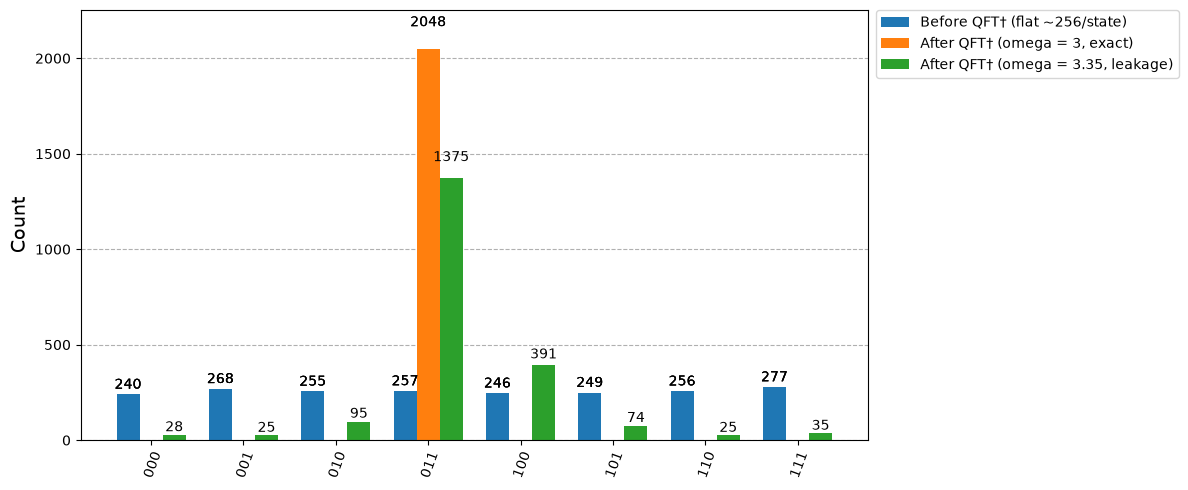

In [5]:
# Combined Qiskit histogram
plot_histogram(
    [before_w3, after_w3, after_w335],
    legend=[
        "Before QFT† (flat ~256/state)",
        "After QFT† (omega = 3, exact)",
        "After QFT† (omega = 3.35, leakage)",
    ],
    figsize=(12, 5),
)

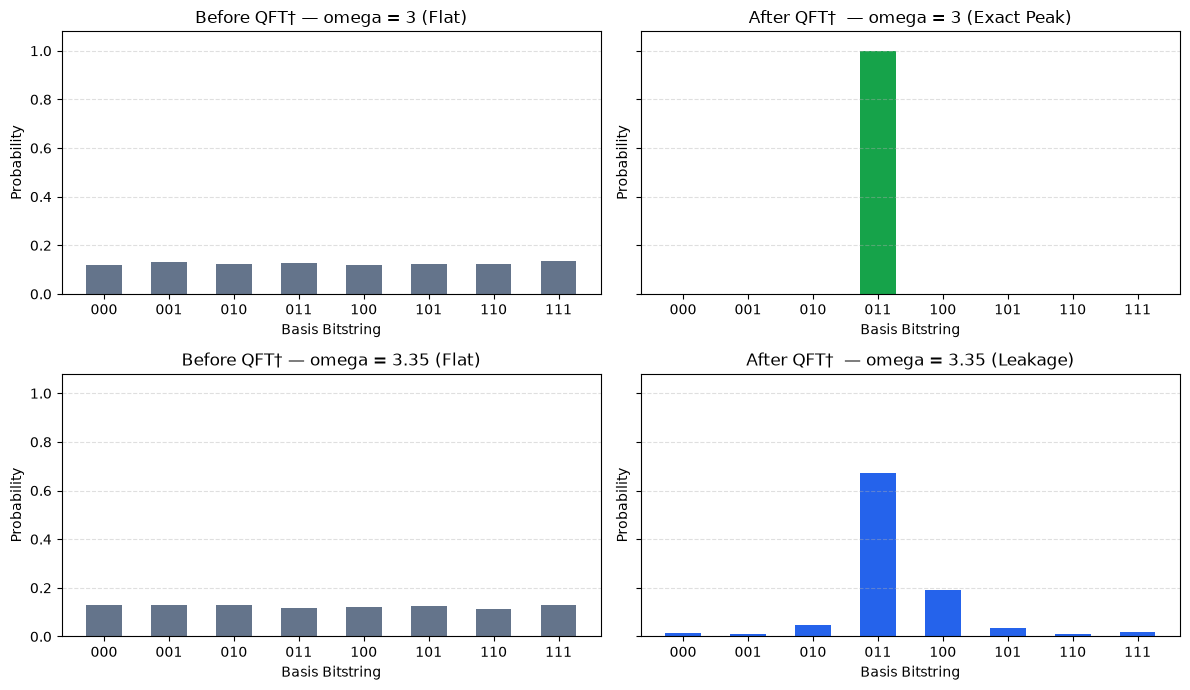

In [6]:
all_bitstrings = [f"{k:03b}" for k in range(8)]

def to_probs(counts, shots=2048):
    return [counts.get(b, 0) / shots for b in all_bitstrings]

panels = [
    ("Before QFT† — omega = 3 (Flat)", to_probs(before_w3), "#64748b"),
    ("After QFT†  — omega = 3 (Exact Peak)", to_probs(after_w3), "#16a34a"),
    ("Before QFT† — omega = 3.35 (Flat)", to_probs(before_w335), "#64748b"),
    ("After QFT†  — omega = 3.35 (Leakage)", to_probs(after_w335), "#2563eb"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, (title, p_vals, color) in zip(axes.flat, panels):
    ax.bar(all_bitstrings, p_vals, color=color, width=0.55)
    ax.set_title(title)
    ax.set_xlabel("Basis Bitstring")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1.08)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## Period Finding on a 3-Qubit Register ($N = 8$)

Suppose we prepare an equal superposition over indices separated by period $r$ (for example, $r = 2 \implies \ket{0}, \ket{2}, \ket{4}, \ket{6}$). Applying forward QFT transforms position-space periodicity into frequency-space peaks separated by $\Delta k = N / r$

In [7]:
def period_finding_experiment(n_qubits: int, period: int, shots: int = 2048):
    N = 2 ** n_qubits
    assert N % period == 0, "Period must divide 2^n cleanly for this demo."

    # Equal superposition over indices x where x % period == 0
    amps = np.zeros(N, dtype=complex)
    indices = [x for x in range(N) if x % period == 0]
    amps[indices] = 1.0 / np.sqrt(len(indices))

    # 1. BEFORE QFT circuit
    qc_before = QuantumCircuit(n_qubits)
    qc_before.initialize(amps, range(n_qubits))
    qc_before_meas = qc_before.copy()
    qc_before_meas.measure_all()
    counts_before = sampler.run([qc_before_meas], shots=shots).result()[0].data.meas.get_counts()

    # 2. AFTER QFT circuit
    qc_after = qc_before.copy()
    qc_after.append(make_qft(n_qubits, inverse=False), range(n_qubits))
    qc_after_meas = qc_after.copy()
    qc_after_meas.measure_all()
    counts_after = sampler.run([qc_after_meas], shots=shots).result()[0].data.meas.get_counts()

    return counts_before, counts_after

In [8]:
# Collect Before & After counts for r = 2 and r = 4
before_r2, after_r2 = period_finding_experiment(n_qubits=3, period=2)
before_r4, after_r4 = period_finding_experiment(n_qubits=3, period=4)

In [9]:
print(before_r2, after_r2)
print(before_r4, after_r4)

{'110': 532, '000': 490, '100': 547, '010': 479} {'000': 1023, '100': 1025}
{'000': 1054, '100': 994} {'010': 497, '100': 509, '110': 520, '000': 522}


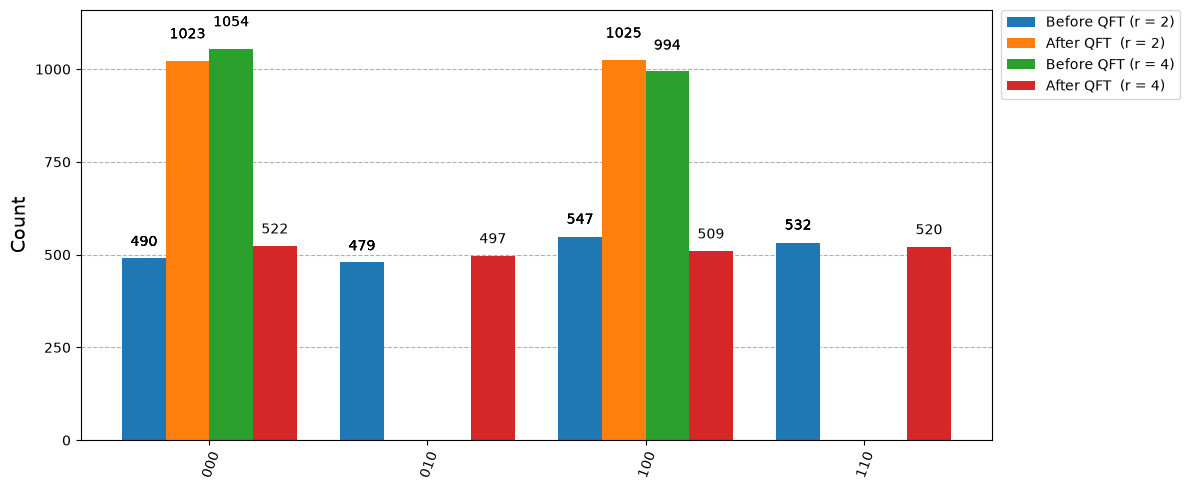

In [11]:
plot_histogram(
    [before_r2, after_r2, before_r4, after_r4],
    legend=[
        "Before QFT (r = 2)",
        "After QFT  (r = 2)",
        "Before QFT (r = 4)",
        "After QFT  (r = 4)",
    ],
    figsize=(12, 5),
)

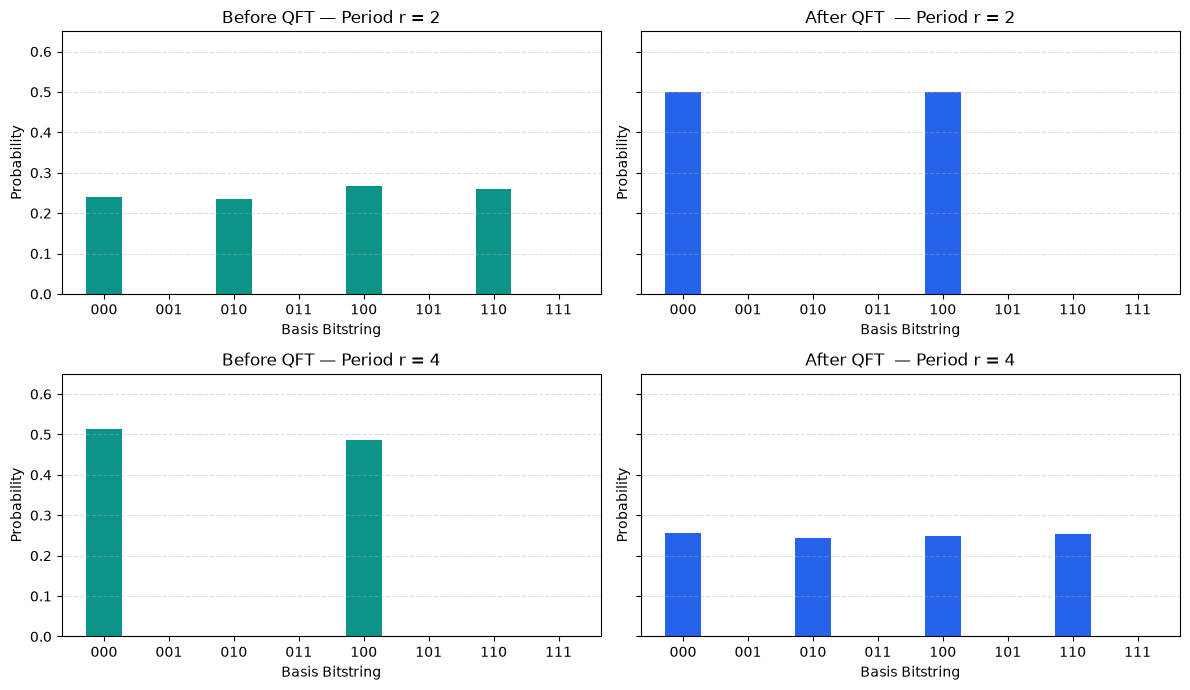

In [10]:
all_bitstrings = [f"{k:03b}" for k in range(8)]

def to_probs(counts, shots=2048):
    return [counts.get(b, 0) / shots for b in all_bitstrings]

panels = [
    ("Before QFT — Period r = 2", to_probs(before_r2), "#0d9488"),
    ("After QFT  — Period r = 2", to_probs(after_r2),  "#2563eb"),
    ("Before QFT — Period r = 4", to_probs(before_r4), "#0d9488"),
    ("After QFT  — Period r = 4", to_probs(after_r4),  "#2563eb"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, (title, p_vals, color) in zip(axes.flat, panels):
    ax.bar(all_bitstrings, p_vals, color=color, width=0.55)
    ax.set_title(title)
    ax.set_xlabel("Basis Bitstring")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 0.65)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()